# Turn amplitude lists into probabilities

This notebook follows **Probability, vectors, and phase**. A probability list gives chances directly. A quantum state vector stores amplitudes in a specified outcome order; squaring their magnitudes gives the probabilities for that measurement basis.

We will keep the outcome labels visible, calculate a complex magnitude, and normalize `[1 + 1j, 2]`. All values below are dimensionless. A mathematical state vector is not a particle's position or a path through space.

## 1. Prepare the calculations

Use NumPy for arrays, magnitudes, and sampling. The plotting settings keep probability bars and amplitude arrows visually distinct. Run this setup before any later cell.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "figure.figsize": (8.4, 3.8),
        "figure.dpi": 120,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": "#24354b",
        "text.color": "#24354b",
        "xtick.color": "#44556c",
        "ytick.color": "#44556c",
        "font.size": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.16,
        "grid.color": "#718198",
        "lines.linewidth": 2.4,
        "savefig.bbox": "tight",
    }
)
BLUE, GREEN, AMBER = "#3c6db3", "#27836d", "#b87920"
rng = np.random.default_rng(20261014)
print(f"Ready: NumPy {np.__version__}, Matplotlib {matplotlib.__version__}")
print("All plots below come from the code in this notebook.")

Ready: NumPy 2.5.4, Matplotlib 3.11.2
All plots below come from the code in this notebook.


## 2. Read a probability list with its labels

In the outcome order `[0, 1]`, the list `[0.75, 0.25]` means a 75% chance of outcome 0 and a 25% chance of outcome 1. A complete probability list contains real, nonnegative values whose sum is one.

Read the values as chances of outcomes, not as amplitudes. The bars below already show probabilities; they should not be squared again.

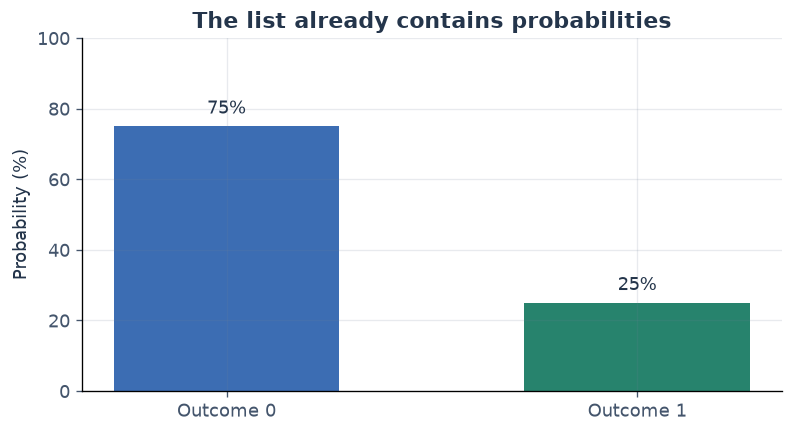

P(0) = 0.75; P(1) = 0.25; sum = 1.00


In [2]:
outcome_labels = ["Outcome 0", "Outcome 1"]
probability_list = np.array([0.75, 0.25])
assert np.all(probability_list >= 0) and np.isclose(probability_list.sum(), 1)
fig, ax = plt.subplots(figsize=(6.5, 3.5), layout="constrained")
bars = ax.bar(outcome_labels, 100 * probability_list, color=[BLUE, GREEN], width=0.55)
ax.bar_label(bars, labels=["75%", "25%"], padding=5)
ax.set(
    ylabel="Probability (%)",
    ylim=(0, 100),
    title="The list already contains probabilities",
)
plt.show()
print(
    f"P(0) = {probability_list[0]:.2f}; P(1) = {probability_list[1]:.2f}; sum = "
    f"{probability_list.sum():.2f}"
)

## 3. Square amplitudes, not probabilities

A normalized state vector can store amplitudes `[0.5, sqrt(0.75)]` in the order `[0, 1]`. For real amplitudes, the probabilities are their squares: `[0.25, 0.75]`.

This explains a common mix-up: an amplitude of `0.5` means probability `0.25`, not `0.5`. The amplitudes themselves do not need to sum to one. Their squared magnitudes do.

Outcome order: [0, 1]
Amplitudes: [0.5      0.866025]
Probabilities: [0.25 0.75]
Amplitude sum = 1.366025; probability sum = 1.000000


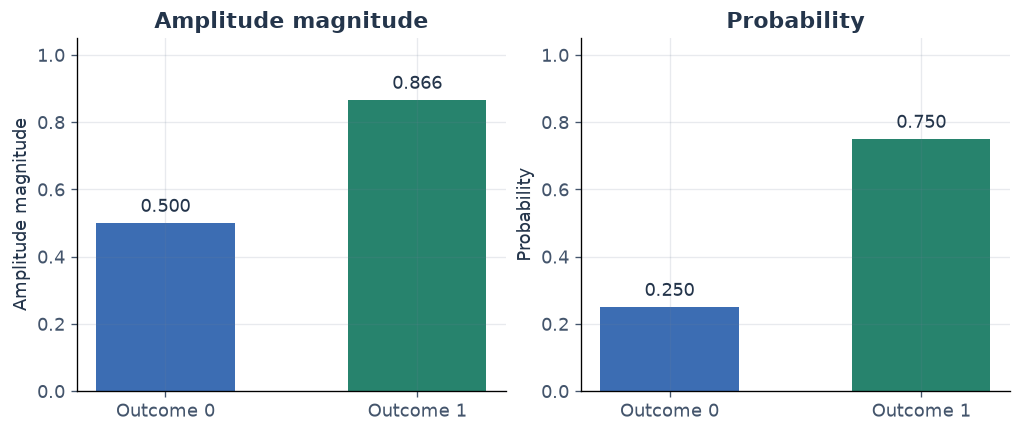

In [3]:
psi_real = np.array([0.5, np.sqrt(0.75)])
probabilities = np.abs(psi_real) ** 2
print("Outcome order: [0, 1]")
print("Amplitudes:", np.round(psi_real, 6))
print("Probabilities:", np.round(probabilities, 6))
print(
    f"Amplitude sum = {psi_real.sum():.6f}; probability sum = {probabilities.sum():.6f}"
)
assert np.allclose(probabilities, [0.25, 0.75])
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.5), layout="constrained")
for ax, values, label in [
    (axes[0], psi_real, "Amplitude magnitude"),
    (axes[1], probabilities, "Probability"),
]:
    bars = ax.bar(outcome_labels, values, color=[BLUE, GREEN], width=0.55)
    ax.bar_label(bars, fmt="%.3f", padding=4)
    ax.set(title=label, ylabel=label, ylim=(0, 1.05))
plt.show()

## 4. Draw a complex amplitude

Python writes `0.3 + 0.4j` for the complex amplitude `0.3 + 0.4i`. Its arrow has real component `0.3`, imaginary component `0.4`, and magnitude `0.5`.

Squared magnitude is `0.3**2 + 0.4**2 = 0.25`. The complex number itself is not a probability. The other arrows, `-0.5` and `0.5j`, have different directions but the same magnitude, so each also gives `0.25` when used as an amplitude for an outcome. These are three separate examples, not a complete normalized three-outcome state.

 0.3 + 0.4i: magnitude = 0.50, probability = 0.25
       −0.5: magnitude = 0.50, probability = 0.25
       0.5i: magnitude = 0.50, probability = 0.25


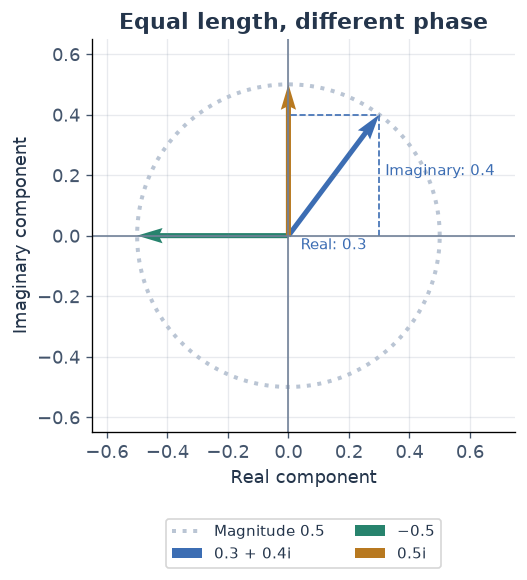

In [4]:
amplitudes = np.array([0.3 + 0.4j, -0.5 + 0j, 0 + 0.5j])
names = ["0.3 + 0.4i", "−0.5", "0.5i"]
fig, ax = plt.subplots(figsize=(6.1, 4.7), layout="constrained")
angle = np.linspace(0, 2 * np.pi, 361)
ax.plot(
    0.5 * np.cos(angle),
    0.5 * np.sin(angle),
    color="#bac5d4",
    linestyle=":",
    label="Magnitude 0.5",
)
for z, name, color in zip(amplitudes, names, [BLUE, GREEN, AMBER]):
    ax.quiver(
        0,
        0,
        z.real,
        z.imag,
        angles="xy",
        scale_units="xy",
        scale=1,
        color=color,
        width=0.012,
        label=name,
    )
    print(f"{name:>11}: magnitude = {abs(z):.2f}, probability = {abs(z) ** 2:.2f}")
ax.plot([0.3, 0.3, 0], [0, 0.4, 0.4], color=BLUE, linestyle="--", linewidth=1)
ax.text(0.15, -0.045, "Real: 0.3", color=BLUE, ha="center", fontsize=9)
ax.text(0.32, 0.2, "Imaginary: 0.4", color=BLUE, fontsize=9)
ax.axhline(0, color="#718198", linewidth=1)
ax.axvline(0, color="#718198", linewidth=1)
ax.set(
    xlabel="Real component",
    ylabel="Imaginary component",
    xlim=(-0.65, 0.75),
    ylim=(-0.65, 0.65),
    aspect="equal",
    title="Equal length, different phase",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=9)
plt.show()
assert np.allclose(np.abs(amplitudes) ** 2, [0.25, 0.25, 0.25])

## 5. Normalize an unscaled vector

The vector `[1 + 1j, 2]` has squared magnitudes `[2, 4]`. Their sum is `6`, so these are not yet a complete probability distribution.

Divide the whole vector by its norm, `sqrt(6)`. Each amplitude gets the same scale factor, so their relative sizes and phases are preserved. The resulting probabilities are `[2/6, 4/6] = [1/3, 2/3]`.

A zero vector cannot be normalized. The function checks that the input is a finite, nonzero one-dimensional vector before dividing.

Raw squared magnitudes: [2. 4.]
Norm = sqrt(6) = 2.449490
Normalized amplitudes: [0.408248+0.408248j 0.816497+0.j      ]
Probabilities: [0.333333 0.666667]
Probability sum = 1.000000


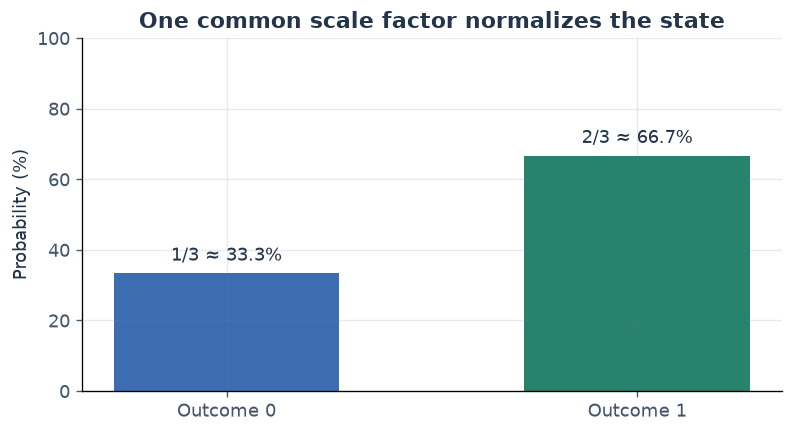

In [5]:
def normalize(vector):
    vector = np.asarray(vector, dtype=complex)
    if vector.ndim != 1 or vector.size == 0 or not np.all(np.isfinite(vector)):
        raise ValueError("Use a finite, nonempty one-dimensional vector.")
    norm = np.linalg.norm(vector)
    if norm == 0 or not np.isfinite(norm):
        raise ValueError("The vector must have a finite nonzero norm.")
    return vector / norm


raw = np.array([1 + 1j, 2], dtype=complex)
psi = normalize(raw)
p = np.abs(psi) ** 2
print("Raw squared magnitudes:", np.abs(raw) ** 2)
print(f"Norm = sqrt(6) = {np.linalg.norm(raw):.6f}")
print("Normalized amplitudes:", np.round(psi, 6))
print("Probabilities:", np.round(p, 6))
print(f"Probability sum = {p.sum():.6f}")
assert np.allclose(p, [1 / 3, 2 / 3])
assert np.isclose(np.vdot(psi, psi), 1)
fig, ax = plt.subplots(figsize=(6.5, 3.5), layout="constrained")
bars = ax.bar(outcome_labels, 100 * p, color=[BLUE, GREEN], width=0.55)
ax.bar_label(bars, labels=["1/3 ≈ 33.3%", "2/3 ≈ 66.7%"], padding=5)
ax.set(
    ylabel="Probability (%)",
    ylim=(0, 100),
    title="One common scale factor normalizes the state",
)
plt.show()

## 6. Keep vector order attached to outcome labels

A vector's order matters. If the basis order remains `[0, 1]`, swapping the two amplitude entries swaps the two outcome predictions.

This is different from merely writing the same state using a different label order: then both the entries and their associated labels would move together. Here we deliberately keep labels fixed and change the state.

Fixed outcome order: [0, 1]
Original probabilities: [0.333333 0.666667]
Swapped-entry probabilities: [0.666667 0.333333]


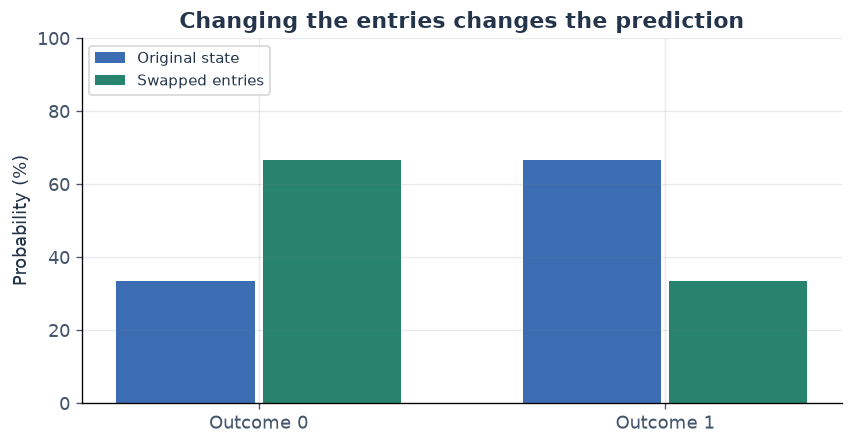

In [6]:
swapped_psi = psi[::-1]
swapped_p = np.abs(swapped_psi) ** 2
print("Fixed outcome order: [0, 1]")
print("Original probabilities:", np.round(p, 6))
print("Swapped-entry probabilities:", np.round(swapped_p, 6))
assert np.allclose(swapped_p, [2 / 3, 1 / 3])
assert np.isclose(swapped_p.sum(), 1)
positions = np.arange(2)
fig, ax = plt.subplots(figsize=(7.0, 3.6), layout="constrained")
ax.bar(positions - 0.18, 100 * p, width=0.34, color=BLUE, label="Original state")
ax.bar(
    positions + 0.18, 100 * swapped_p, width=0.34, color=GREEN, label="Swapped entries"
)
ax.set(
    xticks=positions,
    xticklabels=outcome_labels,
    ylabel="Probability (%)",
    ylim=(0, 100),
    title="Changing the entries changes the prediction",
)
ax.legend(loc="upper left", fontsize=9)
plt.show()

## 7. Sample the normalized prediction

Prepare the same normalized state repeatedly and measure in the outcome basis `[0, 1]`. Draw outcomes from its theoretical distribution.

For 3,000 repetitions, the observed fractions will be close to `[1/3, 2/3]`, with sampling fluctuations. The exact saved counts belong to the stated seed, not to a universal prediction for every experiment.

Detection counts: [1030 1970]
Observed fractions: [0.343333 0.656667]
Theoretical probabilities: [0.333333 0.666667]


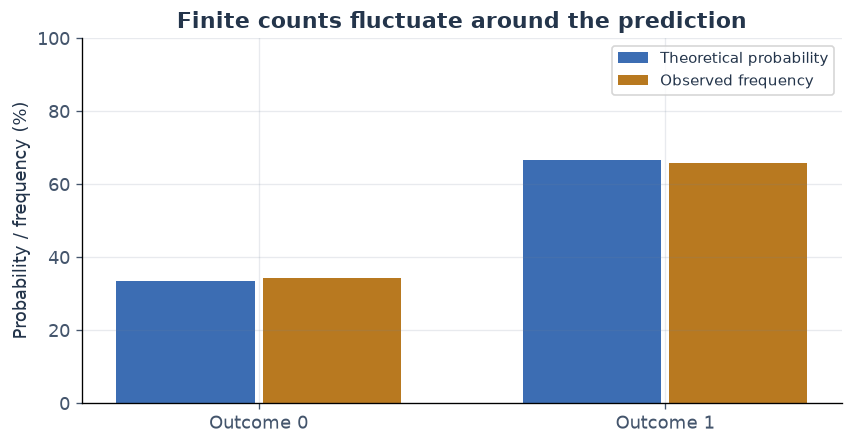

In [7]:
repetitions = 3_000
outcomes = rng.choice(2, size=repetitions, p=p)
counts = np.bincount(outcomes, minlength=2)
observed = counts / repetitions
print("Detection counts:", counts)
print("Observed fractions:", np.round(observed, 6))
print("Theoretical probabilities:", np.round(p, 6))
assert counts.sum() == repetitions
assert np.isclose(observed.sum(), 1)
fig, ax = plt.subplots(figsize=(7.0, 3.6), layout="constrained")
ax.bar(
    positions - 0.18, 100 * p, width=0.34, color=BLUE, label="Theoretical probability"
)
ax.bar(
    positions + 0.18,
    100 * observed,
    width=0.34,
    color=AMBER,
    label="Observed frequency",
)
ax.set(
    xticks=positions,
    xticklabels=outcome_labels,
    ylabel="Probability / frequency (%)",
    ylim=(0, 100),
    title="Finite counts fluctuate around the prediction",
)
ax.legend(fontsize=9)
plt.show()

**Take this with you:** keep the outcome order explicit, square each amplitude's magnitude, and check that the total is one. A state vector can contain signs and complex phases; a probability list cannot preserve all of that information.

**Try a change locally:** replace the raw vector with `[1, 1j]`. Before running, predict its probabilities. You should find equal probabilities, even though its two amplitudes point in different directions. Notebook 03 investigates what that phase difference can change.

Reference: [IBM, fundamentals of quantum information](https://quantum.cloud.ibm.com/learning/courses/basics-of-quantum-information).